In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import copy

import torch
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary

device = "cpu"

In [20]:
transformer = transforms.Compose([transforms.Resize((200,200)), 
                                  transforms.ToTensor(),
                                  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])

path = r"C:\Users\wwwat\Desktop\Corn_data"
data_images = {x:datasets.ImageFolder(os.path.join(path, x), transform=transformer) for x in ["train", "test", "valid"]}
data_loader = {x:DataLoader(data_images[x], shuffle=True, batch_size=64) for x in ["train", "test", "valid"]}

dataset_size = {x:len(data_images[x]) for x in ["test", "train", "valid"]}
class_names = data_images["train"].classes

print(dataset_size)
print(class_names)

name = lambda x: class_names[x]

{'test': 227, 'train': 3781, 'valid': 691}
['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


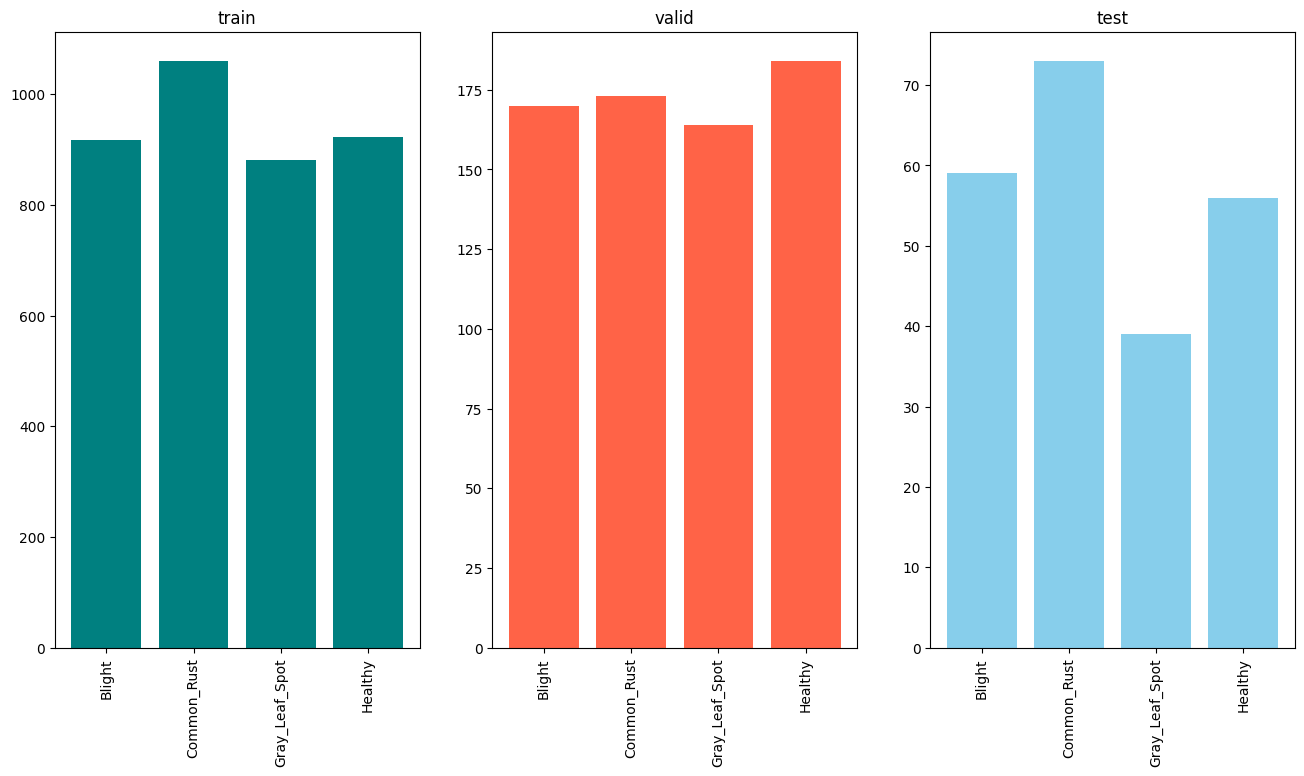

In [21]:
def distribution_plot(section:str):
    chart_labels= np.array([])

    for images, labels in data_loader[section]:
        labels = labels.numpy()
        chart_labels = np.hstack([chart_labels, labels])

    info = np.unique_counts(chart_labels)
    values = list(map(name, info.values.astype(int)))
    counts = info.counts
    return values, counts

values_train, counts_train = distribution_plot("train")
values_valid, counts_valid = distribution_plot("valid")
values_test, counts_test = distribution_plot("test")

plt.figure(figsize=(16,8))
plt.subplot(131);plt.bar(x=values_train, height=counts_train, color="teal");plt.title("train");plt.xticks(rotation=90)
plt.subplot(132);plt.bar(x=values_valid, height=counts_valid, color="tomato");plt.title("valid");plt.xticks(rotation=90)
plt.subplot(133);plt.bar(x=values_test, height=counts_test, color="skyblue");plt.title("test");plt.xticks(rotation=90)
plt.show()

In [22]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.early_stop = False
        self.counter = 0
        self.best_model_state = None

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.best_model_state = model.state_dict()
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = model.state_dict()
            self.counter = 0

    def load_best_model(self, model):
        model.load_state_dict(self.best_model_state)

In [23]:
model = models.resnet50(pretrained=True)
for param in model.parameters():
    param.requires_grad = False

fc_in_fwatures = model.fc.in_features
model.fc = nn.Linear(fc_in_fwatures, 4)



criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
early_stopping = EarlyStopping(patience=8, delta=0.01)
lr_scheduler_step = optim.lr_scheduler.StepLR(optimizer=optimizer, step_size=6, gamma=0.1)

summary(model, (3,200,200))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 100, 100]           9,408
       BatchNorm2d-2         [-1, 64, 100, 100]             128
              ReLU-3         [-1, 64, 100, 100]               0
         MaxPool2d-4           [-1, 64, 50, 50]               0
            Conv2d-5           [-1, 64, 50, 50]           4,096
       BatchNorm2d-6           [-1, 64, 50, 50]             128
              ReLU-7           [-1, 64, 50, 50]               0
            Conv2d-8           [-1, 64, 50, 50]          36,864
       BatchNorm2d-9           [-1, 64, 50, 50]             128
             ReLU-10           [-1, 64, 50, 50]               0
           Conv2d-11          [-1, 256, 50, 50]          16,384
      BatchNorm2d-12          [-1, 256, 50, 50]             512
           Conv2d-13          [-1, 256, 50, 50]          16,384
      BatchNorm2d-14          [-1, 256,

In [24]:
epochs = 60

train_loss = []
train_accuracy = []
val_loss = []
val_accuracy = []


for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")

    total = 0
    correct = 0
    running_loss = 0.0

    model.train()
    for inputs, labels in data_loader['train']:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        predictions = torch.argmax(outputs, dim=1)

        loss.backward()
        optimizer.step()

        total += labels.size(0)
        running_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()

    train_accuracy.append(100 * correct / total)
    train_loss.append(running_loss / dataset_size['train'])

    lr_scheduler_step.step()
    print(f"Train Accuracy: {100 * correct/total:.2f}%   Train Loss: {running_loss/dataset_size['train']:.5f}")
    # ---------

    model.eval()
    with torch.no_grad():
        total = 0
        correct = 0
        running_loss = 0.0

        for inputs, labels in data_loader['valid']:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()
            running_loss += loss.item() * labels.size(0)

        val_accuracy.append(100 * correct / total)
        val_loss.append(running_loss / dataset_size['valid'])

        print(f"Val Accuracy: {correct/total:.2f}%   Val Loss: {running_loss/dataset_size['valid']:.5f}")


        early_stopping(running_loss/dataset_size['valid'], model=model)
        if early_stopping.early_stop:
            print("Early Stopping")
            break

print("Training Process got finish")
early_stopping.load_best_model(model)

torch.save(model.state_dict(), r"C:\Users\wwwat\Desktop\Corn Leaf Disease\resnet50\resnet50_model.pth")    

Epoch 1/60
Train Accuracy: 77.89%   Train Loss: 0.70594
Val Accuracy: 0.88%   Val Loss: 0.43367
Epoch 2/60
Train Accuracy: 88.89%   Train Loss: 0.37189
Val Accuracy: 0.89%   Val Loss: 0.33957
Epoch 3/60
Train Accuracy: 90.40%   Train Loss: 0.30516
Val Accuracy: 0.90%   Val Loss: 0.31387
Epoch 4/60
Train Accuracy: 90.45%   Train Loss: 0.27492
Val Accuracy: 0.90%   Val Loss: 0.28945
Epoch 5/60
Train Accuracy: 91.30%   Train Loss: 0.25604
Val Accuracy: 0.91%   Val Loss: 0.27947
Epoch 6/60
Train Accuracy: 91.96%   Train Loss: 0.24044
Val Accuracy: 0.91%   Val Loss: 0.26899
Epoch 7/60
Train Accuracy: 92.75%   Train Loss: 0.21683
Val Accuracy: 0.92%   Val Loss: 0.26503
Epoch 8/60
Train Accuracy: 92.73%   Train Loss: 0.22161
Val Accuracy: 0.91%   Val Loss: 0.26520
Epoch 9/60
Train Accuracy: 92.78%   Train Loss: 0.21688
Val Accuracy: 0.91%   Val Loss: 0.26249
Epoch 10/60
Train Accuracy: 92.33%   Train Loss: 0.22007
Val Accuracy: 0.91%   Val Loss: 0.26242
Epoch 11/60
Train Accuracy: 92.25%   Tr

In [16]:
with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\resnet50\train_loss.npy", "wb") as f:
    np.save(f, train_loss)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\resnet50\train_accuracy.npy", "wb") as f:
    np.save(f, train_accuracy)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\resnet50\val_loss.npy", "wb") as f:
    np.save(f, val_loss)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\resnet50\val_accuracy.npy", "wb") as f:
    np.save(f, val_accuracy)